In [7]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import RelaxationTissueModel

microtorch_model = ModelMaker("SphereBallAstrosticks")
sphere, ball, astrosticks = microtorch_model.compartments

# Sphere's diffusivity is fixed inside the compartment, not a model parameter.
sphere.fixed_D = 2

# Make Astrosticks use a fixed D_par of 8.0.
astrosticks.fixed_D_par = 8.0
astrosticks.parameter_ranges = [[8.0, 8.0]]
microtorch_model.parameter_ranges[-1, :] = [8.0, 8.0]

model = MicrotorchTissueModel(
    microtorch_model,
    parameters={
        "radius": 6.0,  # Sphere radius
        "D": 2,        # Ball diffusivity
        "D_par": 8.0,    # Astrosticks parallel diffusivity
        "f_0": 0.6,      # Sphere
        "f_1": 0.3,      # Ball
        "f_2": 0.1,      # Astrosticks; derived from f_0 and f_1
    },
)

# Keep the Ball and Astrosticks diffusivities fixed during fitting.
for name in ("D", "D_par"):
    model[name].optimize = False
    model[name].fit_flag = False



model["radius"].value_list = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14,15]

model = RelaxationTissueModel(model=model, t2=0.1)



model["T2"].optimize = False
model["T2"].fit_flag = False
print("Sphere fixed diffusivity:", sphere.fixed_D)
print(model)

No YAML configuration found for SphereBallAstrosticks model.
Falling back to parsing model name for compartments: ['Sphere', 'Ball', 'Astrosticks'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  SphereBallAstrosticks
########### Compartments: ['Sphere', 'Ball', 'Astrosticks']
########### Parameter names: [['radius'], ['D'], ['D_par']]
########### Parameter ranges: [[[0.001, 15]], [[0.001, 3]], [[0.5, 3.0]]]
-----------
Sphere fixed diffusivity: 2
Tissue model with 8 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_radius            6      1      True        True   (0.001, 15.0)
model_D                 2      1      False       False  (0.001, 3.0)
model_D_par             8      1      False       False  (8.0, 8.0)
model_f_0               0.6    1      True        True   (0.0, 1.0)
model_f_1               0.3    1      True  

In [8]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 5
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28]
Gradient-magnitude free indices: [ 1  8 15 22 29]
b0 gradient magnitudes: [-0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False]
Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.08)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                          

In [9]:
from copy import deepcopy
import numpy as np

scheme = deepcopy(initial_scheme)
x0 = scheme.scaled_free_parameter_vector.copy()

for name, constraint in scheme.constraints.items():
    scheme.set_scaled_free_parameter_vector(x0)
    values = np.atleast_1d(constraint.fun(x0))
    print(
        name,
        "values:", values.shape,
        "lower bounds:", np.shape(constraint.lb),
        "upper bounds:", np.shape(constraint.ub),
    )

scheme.set_scaled_free_parameter_vector(x0)

PulseIntervalLargerThanPulseDuration values: (35,) lower bounds: () upper bounds: ()
PulseMagnitudeSmallerThanMaxMagnitude values: (35,) lower bounds: () upper bounds: ()
EchoTimeLargerThanMinEchoTime values: (35,) lower bounds: () upper bounds: ()
BValueWithinBounds values: (30,) lower bounds: () upper bounds: ()


In [10]:
signal = model(initial_scheme)
print(signal)

[0.40656966 0.21383714 0.21383714 0.21383714 0.21383714 0.21383714
 0.21383714 0.51170858 0.25947598 0.25947598 0.25947598 0.25947598
 0.25947598 0.25947598 0.40656966 0.24052159 0.24052159 0.24052159
 0.24052159 0.24052159 0.24052159 0.52204578 0.37553686 0.37553686
 0.37553686 0.37553686 0.37553686 0.37553686 0.60653066 0.55932372
 0.55932372 0.55932372 0.55932372 0.55932372 0.55932372]


In [11]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)
print(jacobian.shape)

[[ 0.          0.          0.        ]
 [-0.02076806  0.27005746 -0.07255492]
 [-0.02076806  0.27005746 -0.07255492]
 [-0.02076806  0.27005746 -0.07255492]
 [-0.02076806  0.27005746 -0.07255492]
 [-0.02076806  0.27005746 -0.07255492]
 [-0.02076806  0.27005746 -0.07255492]
 [ 0.          0.          0.        ]
 [-0.0296767   0.29548602 -0.10400571]
 [-0.0296767   0.29548602 -0.10400571]
 [-0.0296767   0.29548602 -0.10400571]
 [-0.0296767   0.29548602 -0.10400571]
 [-0.0296767   0.29548602 -0.10400571]
 [-0.0296767   0.29548602 -0.10400571]
 [ 0.          0.          0.        ]
 [-0.01138972  0.26940315 -0.083775  ]
 [-0.01138972  0.26940315 -0.083775  ]
 [-0.01138972  0.26940315 -0.083775  ]
 [-0.01138972  0.26940315 -0.083775  ]
 [-0.01138972  0.26940315 -0.083775  ]
 [-0.01138972  0.26940315 -0.083775  ]
 [ 0.          0.          0.        ]
 [-0.00942825  0.2612529  -0.03817977]
 [-0.00942825  0.2612529  -0.03817977]
 [-0.00942825  0.2612529  -0.03817977]
 [-0.00942825  0.2612529 

In [12]:
from microtool.optimize import optimize_scheme

optimal_scheme, _ = optimize_scheme(initial_scheme, model, noise_variance=0.05, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 100,
    #"finite_diff_rel_step": 1e-8,  # Prevents large jumps during gradient estimation
    #"initial_tr_radius": 0.05        # Prevents trust radius from jumping to 35.0
})

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/tissue_model.py:540: UserWarning: If T2 relaxation is not used for fitting, echo time should be fixed.
  warnings.warn("If T2 relaxation is not used for fitting, echo time should be fixed.")


| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |  21   |   0   | +5.3709e+03 | 1.00e+00 | 3.88e+08 | 0.00e+00 |
|   2   |  42   |   1   | +4.9539e+03 | 1.00e+00 | 9.47e+07 | 1.37e-02 |
|   3   |  63   |  10   | +4.3378e+03 | 1.00e+00 | 2.90e+08 | 0.00e+00 |
|   4   |  84   |  14   | +4.3378e+03 | 5.00e-01 | 2.90e+08 | 0.00e+00 |
|   5   |  105  |  18   | +4.3378e+03 | 2.50e-01 | 2.90e+08 | 0.00e+00 |
|   6   |  126  |  20   | +4.3378e+03 | 1.25e-01 | 2.90e+08 | 0.00e+00 |
|   7   |  147  |  23   | +4.2391e+03 | 1.25e-01 | 1.56e+08 | 0.00e+00 |
|   8   |  168  |  24   | +4.2391e+03 | 6.25e-02 | 1.56e+08 | 0.00e+00 |
|   9   |  189  |  25   | +4.2352e+03 | 6.25e-02 | 3.89e+07 | 0.00e+00 |
|  10   |  210  |  29   | +4.2352e+03 | 3.12e-02 | 3.89e+07 | 0.00e+00 |
|  11   |  231  |  32   | +4.2352e+03 | 1.56e-02 | 3.89e+07 | 0.00e+00 |
|  12   |  252  |  36   | +4.3035e+03 | 1.09e-01 | 

KeyboardInterrupt: 

In [ ]:
print(optimal_scheme)
print(optimal_scheme.b_values)
print("Test")

Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.08)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                      -0                                          1.92731                                     1.5708                                        0.026776                                     0.0444548                      0.091975
                                       0.0366491                                  2.2988                             

In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

model["radius"].value =12
print(model)


# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result

Tissue model with 7 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
radius                 12          1  True        True   (0.001, 15.0)
D                       2          1  False       False  (0.001, 3.0)
D_par                   8          1  False       False  (8.0, 8.0)
f_0                     0.6        1  True        True   (0.0, 1.0)
f_1                     0.3        1  True        True   (0.0, 1.0)
f_2                     0.1        1  False       False  (0.0, 1.0)
S0                      1          1  False       False  (0.0, 2.0)


Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:09<00:00, 110.24it/s]


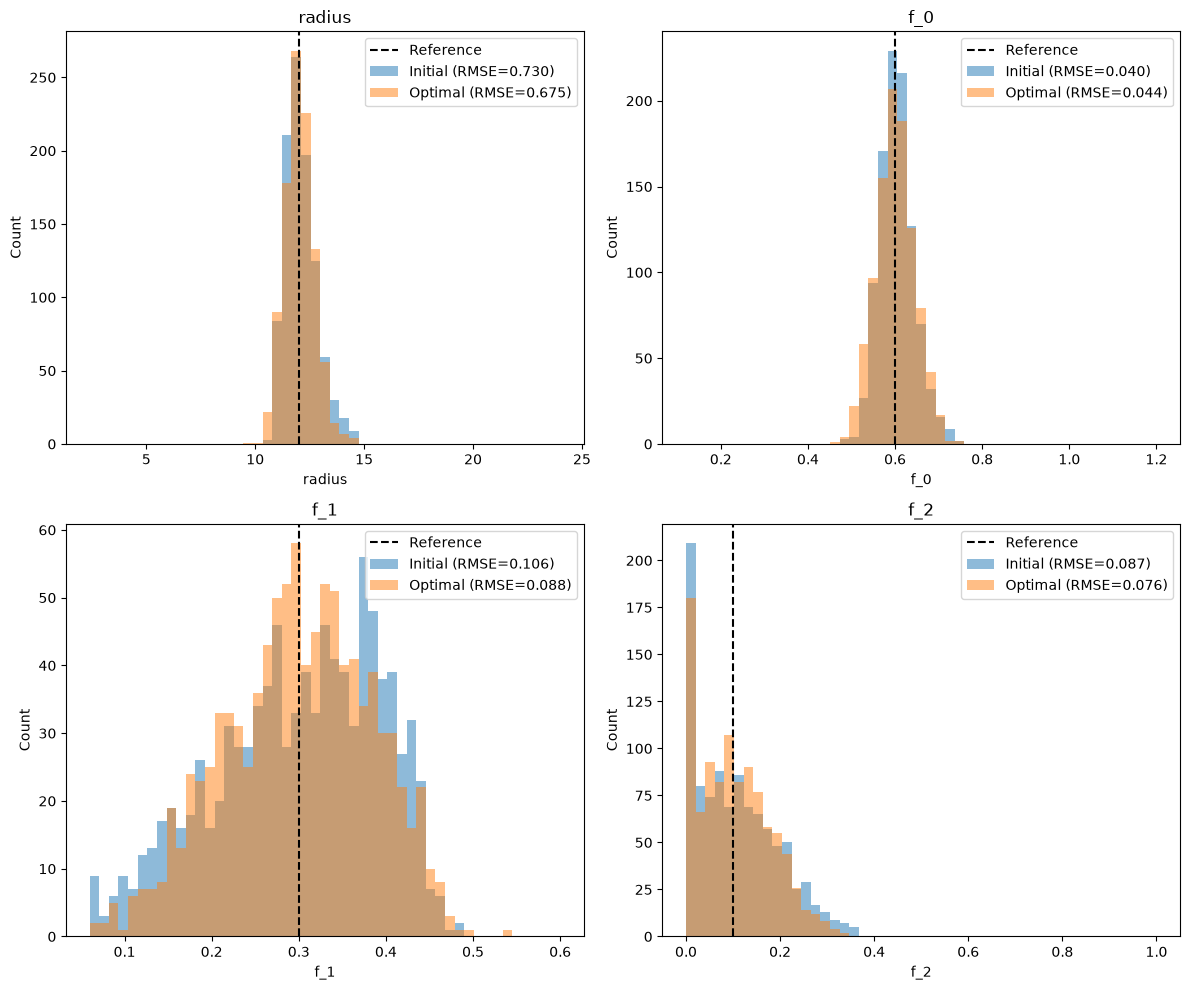

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

initial_result = initial
optimal_result = optimal

# Derived fraction f_2 = 1 - f_0 - f_1
initial_f2 = 1 - initial_result["f_0"] - initial_result["f_1"]
optimal_f2 = 1 - optimal_result["f_0"] - optimal_result["f_1"]
reference_f2 = 1 - model["f_0"].value - model["f_1"].value

# Define data mapping: (title, reference_val, initial_vals, optimal_vals, bins)
radius_ref = model["radius"].value
f0_ref = model["f_0"].value
f1_ref = model["f_1"].value

plots_data = [
    (
        "radius",
        radius_ref,
        initial_result["radius"],
        optimal_result["radius"],
        np.linspace(0.2 * radius_ref, 2 * radius_ref, 50),
    ),
    (
        "f_0",
        f0_ref,
        initial_result["f_0"],
        optimal_result["f_0"],
        np.linspace(0.2 * f0_ref, 2 * f0_ref, 50),
    ),
    (
        "f_1",
        f1_ref,
        initial_result["f_1"],
        optimal_result["f_1"],
        np.linspace(0.2 * f1_ref, 2 * f1_ref, 50),
    ),
    (
        "f_2",
        reference_f2,
        initial_f2,
        optimal_f2,
        np.linspace(0, 1, 50),
    ),
]

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, ref, init_vals, opt_vals, bins) in zip(axes, plots_data):
    init_rmse = np.sqrt(np.mean((init_vals - ref) ** 2))
    opt_rmse = np.sqrt(np.mean((opt_vals - ref) ** 2))

    ax.axvline(ref, color="black", linestyle="--", label="Reference")
    ax.hist(
        init_vals,
        bins=bins,
        alpha=0.5,
        label=f"Initial (RMSE={init_rmse:.3f})",
    )
    ax.hist(
        opt_vals,
        bins=bins,
        alpha=0.5,
        label=f"Optimal (RMSE={opt_rmse:.3f})",
    )

    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()